# 01 - Exploratory Data Analysis: UCI Heart Disease (Cleveland)

Input: `data/processed/heart_clean.csv` (made by `src/preprocess.py`).
Plots are saved to `screenshots/eda/` for the report.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# The notebook runs from notebooks/, so paths go up one level
DATA_FILE = Path("../data/processed/heart_clean.csv")
FIG_DIR = Path("../screenshots/eda")
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_FILE)
print(df.shape)
df.head()

Matplotlib is building the font cache; this may take a moment.


(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0,6,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3,3,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2,7,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0,3,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0,3,0


## Basic info and summary statistics

In [2]:
print("Missing values per column:")
print(df.isna().sum().to_string())
df.describe().T

Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


## Class balance
How many patients have heart disease (1) and how many don't (0)?

target
0    164
1    139
Name: count, dtype: int64
target
0    54.1 %
1    45.9 %
Name: count, dtype: str


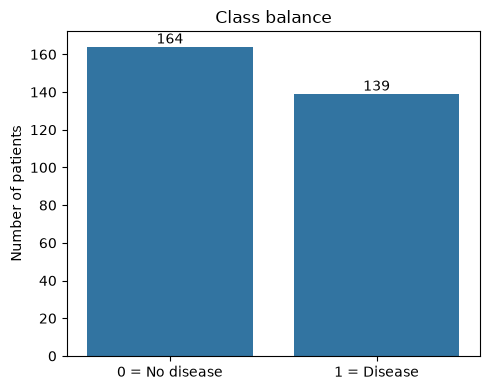

In [3]:
counts = df["target"].value_counts().sort_index()
print(counts)
print((counts / len(df) * 100).round(1).astype(str) + " %")

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x="target", data=df, ax=ax)
ax.set_xticks([0, 1], ["0 = No disease", "1 = Disease"])
ax.set_xlabel("")
ax.set_ylabel("Number of patients")
ax.set_title("Class balance")
# Write the count on top of each bar
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
fig.savefig(FIG_DIR / "class_balance.png", dpi=120)
plt.show()

## Histograms of the numeric features
These five columns are real measurements. The other columns are category codes.

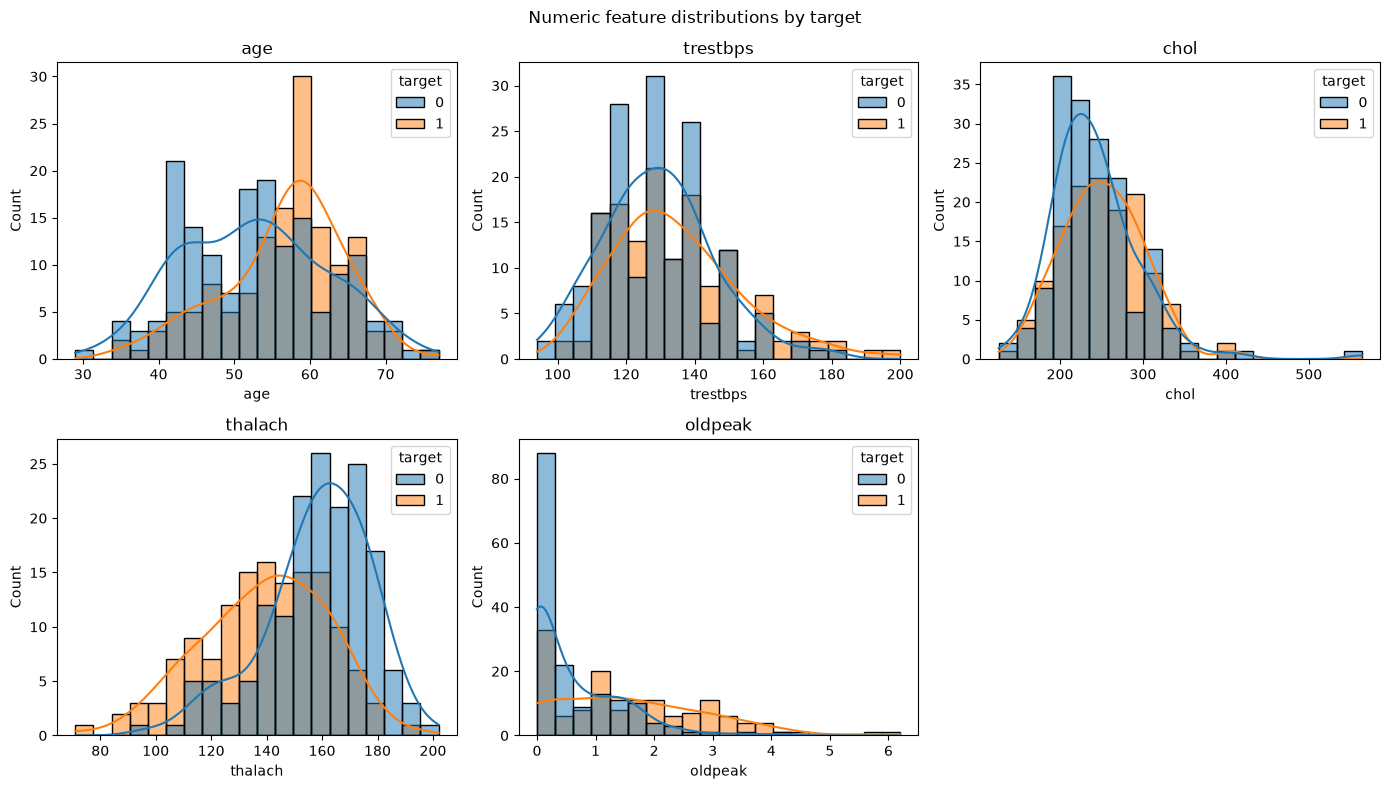

In [4]:
numeric_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, numeric_cols):
    # Colour by target so we can see which features separate the two classes
    sns.histplot(data=df, x=col, hue="target", kde=True, ax=ax, bins=20)
    ax.set_title(col)
axes.flat[-1].axis("off")  # 5 plots in a 2x3 grid, so hide the empty one
plt.suptitle("Numeric feature distributions by target")
plt.tight_layout()
fig.savefig(FIG_DIR / "numeric_histograms.png", dpi=120)
plt.show()

## Correlation heatmap

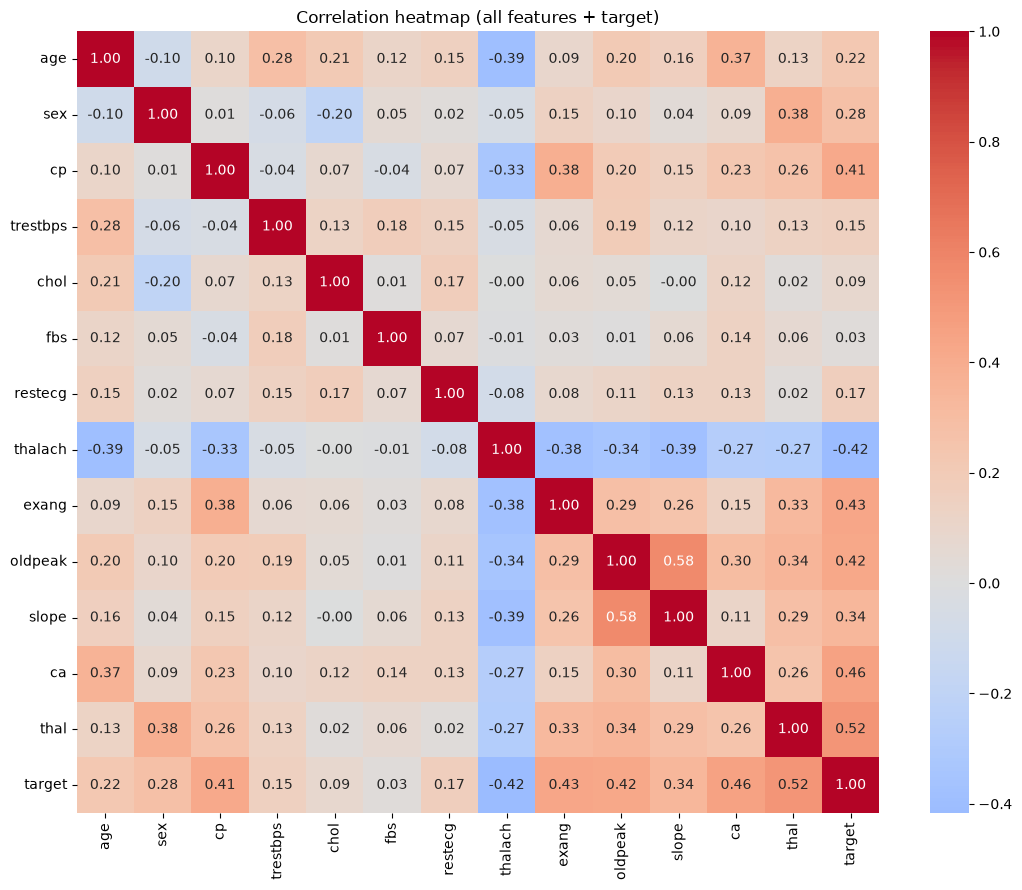

Correlation with target:
thal        0.52
ca          0.46
exang       0.43
oldpeak     0.42
thalach    -0.42
cp          0.41
slope       0.34
sex         0.28
age         0.22
restecg     0.17
trestbps    0.15
chol        0.09
fbs         0.03


In [5]:
corr = df.corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation heatmap (all features + target)")
plt.tight_layout()
fig.savefig(FIG_DIR / "correlation_heatmap.png", dpi=120)
plt.show()

# Which features move most with the target?
print("Correlation with target:")
print(corr["target"].drop("target").sort_values(key=abs, ascending=False).round(2).to_string())

## Key observations
- **Class balance:** 164 without disease vs 139 with disease (about 54% / 46%). The classes are close to balanced, so accuracy is a fair metric, and we will also report precision, recall and ROC-AUC.
- **Strongest signals:** `thal` (0.52), `ca` (0.46), `exang` (0.43), `oldpeak` (0.42), `thalach` (-0.42) and `cp` (0.41) have the largest correlation with the target. A lower max heart rate (`thalach`) goes with disease.
- **Weak signals:** `chol` and `fbs` barely correlate with the target on their own (0.09 and 0.03).
- **Scales differ** (e.g. `chol` is around 250 while `oldpeak` is around 1), so we will scale numeric features in Step 2. Category codes such as `cp` and `thal` will be one-hot encoded.